<p style="text-align:center">
    <a href="https://www.ict.mahidol.ac.th/en/" target="_blank">
    <img src="https://www3.ict.mahidol.ac.th/ICTSurveysV2/Content/image/MUICT2.png" width="400" alt="Faculty of ICT">
    </a>
</p>

# ITGE275: Economics
## Session 4: Market Dynamics – Equilibrium, Floating Prices, and Oil

---
### 👦 Student Information 👧

**Your name:** Qimin Zhu
**ID:** 6888143

---

### **1. Introduction: The System in Balance**

In previous sessions, we studied the **Consumer** (Demand) and the **Producer** (Supply) in isolation. Today, we bring them together.

A market is a distributed computing system where:
1.  **Consumers** broadcast their willingness to pay (Demand Curve).
2.  **Producers** broadcast their willingness to sell (Supply Curve).
3.  **The Price ($P$)** acts as a signal that synchronizes these two groups.

**Market Equilibrium** occurs where Quantity Demanded equals Quantity Supplied ($Q_d = Q_s$). At this point, there is no waste (Surplus) and no hunger (Shortage).

We will also explore **Oil Prices** as a case study for volatile, floating prices that impact the entire global economy.

In [46]:
# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display

# Configure plotting style
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries loaded successfully.")

Libraries loaded successfully.


### **2. The Math of Equilibrium**

We can model the market with two linear equations:

1.  **Demand Function:** $Q_d = a - bP$
    * $a$: Total market size (Intercept).
    * $b$: Price sensitivity of consumers.
2.  **Supply Function:** $Q_s = c + dP$
    * $c$: Baseline supply (often negative, implying a min price is needed to start).
    * $d$: Producer sensitivity to price.

**Equilibrium Algorithm:**
Set $Q_d = Q_s$ and solve for $P^*$.

$$ a - bP = c + dP $$
$$ a - c = P(b + d) $$
$$ P^* = \frac{a - c}{b + d} $$

In [47]:
def solve_equilibrium(a, b, c, d):
    """
    Solves for Equilibrium Price (P_star) and Quantity (Q_star).
    Demand: Q = a - bP
    Supply: Q = c + dP
    """
    if (b + d) == 0:
        return None, None # Parallel lines
    
    p_star = (a - c) / (b + d)
    q_star = a - (b * p_star)
    
    return p_star, q_star

# Example Calculation
# Demand: Q = 200 - 10P
# Supply: Q = 50 + 5P
P_eq, Q_eq = solve_equilibrium(200, 10, 50, 5)

print(f"Equilibrium Price (P*):    ${P_eq:.2f}")
print(f"Equilibrium Quantity (Q*): {Q_eq:.2f} units")

Equilibrium Price (P*):    $10.00
Equilibrium Quantity (Q*): 100.00 units


### **3. Interactive Simulation: Market Shocks**

Markets are never static. They are hit by **Shocks**:
* **Demand Shocks:** Consumer panic, viral trends, income changes.
* **Supply Shocks:** New technology (Good), Natural disasters (Bad), Oil rig failures (Bad).

Use the simulator below to act as the "Invisible Hand".

**Controls:**
* **Demand Intercept ($a$):** Increase this to simulate a Demand Boom.
* **Supply Intercept ($c$):** Decrease this to simulate a Supply Shock (Disaster).



In [54]:
def plot_market(demand_shift, supply_shift):
    # Base Parameters
    b, d = 2, 2  # Slopes
    
    # Modified Intercepts based on sliders
    a = 100 + demand_shift
    c = 20 + supply_shift - 20
    
    # Price Range for plotting
    prices = np.linspace(0, 50, 100)
    
    # Calculate Curves
    qd = a - b * prices
    qs = c + d * prices
    
    # Solve for Equilibrium
    p_star, q_star = solve_equilibrium(a, b, c, d)
    
    # Plotting
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Plot Lines
    ax.plot(qd, prices, label='Demand', color='blue', linewidth=3)
    ax.plot(qs, prices, label='Supply', color='red', linewidth=3)
    
    # Plot Equilibrium Point
    ax.scatter([q_star], [p_star], color='black', s=150, zorder=5, label='Equilibrium')
    
    # Dotted Guide Lines
    ax.hlines(p_star, 0, q_star, linestyle='--', color='gray')
    ax.vlines(q_star, 0, p_star, linestyle='--', color='gray')
    
    # Annotations
    ax.text(q_star + 5, p_star, f'  P*=${p_star:.2f}', fontsize=12, verticalalignment='center')
    ax.text(q_star, p_star - 2, f'Q*={q_star:.1f}', fontsize=12, horizontalalignment='center')

    # Setup Graph
    ax.set_title(f'Market Dynamics Simulator', fontsize=14)
    ax.set_xlabel('Quantity')
    ax.set_ylabel('Price ($)')
    ax.set_xlim(0, 200)
    ax.set_ylim(0, 50)
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.show()

# Create Widgets
style = {'description_width': 'initial'}

widgets.interactive(plot_market,
    demand_shift=widgets.FloatSlider(min=-40, max=40, step=5, value=0, description='Demand Shock (Consumer Mood)', style=style),
    supply_shift=widgets.FloatSlider(min=-40, max=40, step=5, value=0, description='Supply Shock (Technology/Disaster)', style=style)
)

interactive(children=(FloatSlider(value=0.0, description='Demand Shock (Consumer Mood)', max=40.0, min=-40.0, …

### **4. Case Study: Global Oil & Transport Costs**

Oil is the "Master Resource." Changes in oil prices affect almost every sector, especially Transportation.

We will analyze a synthetic dataset that mirrors real-world events:
1.  **2020 Pandemic:** Demand collapses (Travel bans). Price crashes.
2.  **2022 Geopolitical Conflict:** Supply shock (Sanctions). Price spikes.

We will check the correlation between **Oil Prices** and **Airline Stock Prices** (Cost vs. Profit).

,Global_Oil_Price_USD,Airline_Stock_Index,Thai_Diesel_THB
Date,,,
2019-01-31,62.483571,98.562477,28.745071
2019-02-28,59.308678,99.443023,27.792604
2019-03-31,63.238443,96.680995,28.971533
2019-04-30,67.615149,96.411380,30.284545
2019-05-31,58.829233,102.437577,27.648770


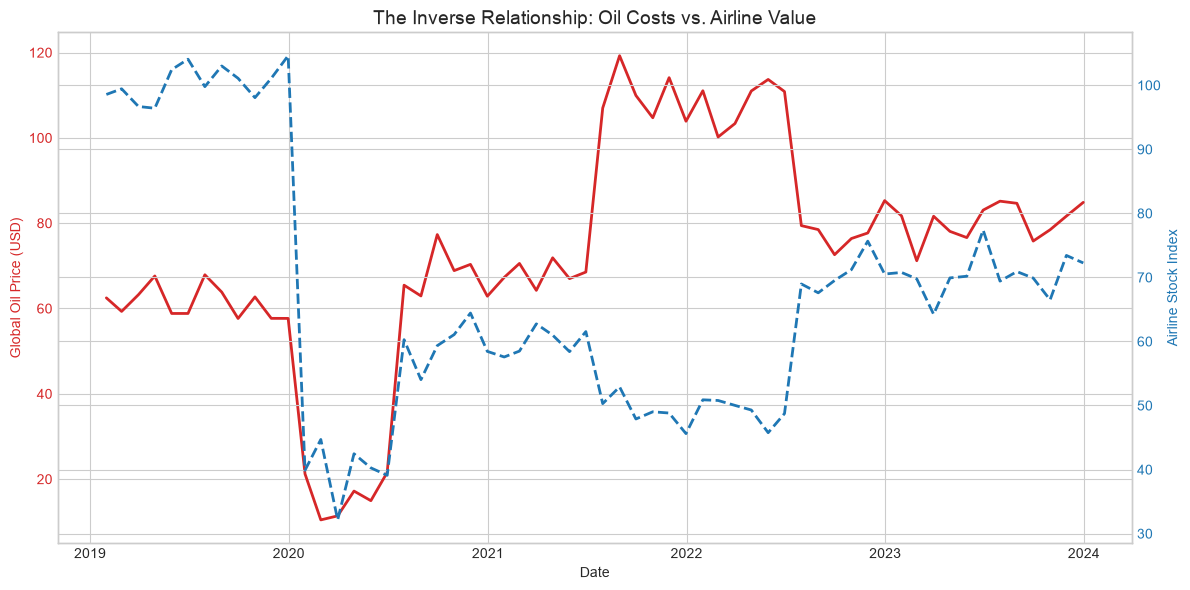

In [49]:
# === DATA GENERATION (Synthetic Data mimicking FRED/Stock Market) ===
np.random.seed(42)
dates = pd.date_range(start='2019-01-01', end='2023-12-31', freq='ME')

# 1. Simulate Oil Prices (Brent Crude)
# Trend: Stable -> Crash (2020) -> Recovery -> Spike (2022) -> Normalize
oil_trend = np.array([60]*12 + [20]*6 + [70]*12 + [110]*12 + [80]*18)
oil_noise = np.random.normal(0, 5, 60)
oil_prices = oil_trend + oil_noise

# 2. Simulate Airline Stock Index
# Inverse correlation with oil, plus demand shocks
airline_trend = np.array([100]*12 + [40]*6 + [60]*12 + [50]*12 + [70]*18)
airline_noise = np.random.normal(0, 3, 60)
airline_stocks = airline_trend + airline_noise

# 3. Simulate Thai Retail Diesel Price (Local Pass-through)
# Usually stabilized by Oil Fund, so less volatile
thai_diesel = (oil_prices * 0.3) + 10  # Simple linear relation + subsidy smoothing
thai_diesel = np.clip(thai_diesel, 20, 35) # Cap at 35 THB (Government cap)

# Create DataFrame
df = pd.DataFrame({
    'Date': dates,
    'Global_Oil_Price_USD': oil_prices,
    'Airline_Stock_Index': airline_stocks,
    'Thai_Diesel_THB': thai_diesel
})
df.set_index('Date', inplace=True)

display(df.head())

# === VISUALIZATION ===
fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:red'
ax1.set_xlabel('Date')
ax1.set_ylabel('Global Oil Price (USD)', color=color)
ax1.plot(df.index, df['Global_Oil_Price_USD'], color=color, linewidth=2, label='Oil Price')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  # Instantiate a second axes that shares the same x-axis
color = 'tab:blue'
ax2.set_ylabel('Airline Stock Index', color=color)
ax2.plot(df.index, df['Airline_Stock_Index'], color=color, linewidth=2, linestyle='--', label='Airline Stocks')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('The Inverse Relationship: Oil Costs vs. Airline Value', fontsize=14)
fig.tight_layout()
plt.show()

### **5. Correlation Analysis**

In Data Science, we quantify relationships using **Correlation** ($-1$ to $+1$).

* **+1:** Moving perfectly together (e.g., Oil Price vs. Gasoline Price).
* **-1:** Moving perfectly opposite (e.g., Oil Price vs. Transport Company Profit).
* **0:** No relationship.

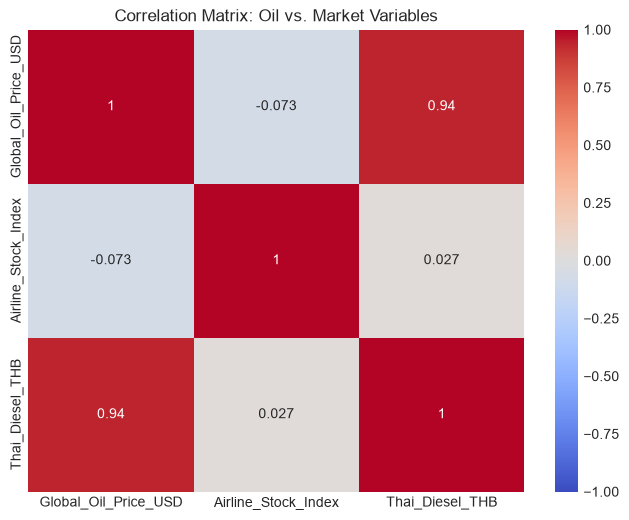

In [50]:
# Calculate Correlation Matrix
corr_matrix = df.corr()

# Plot Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlation Matrix: Oil vs. Market Variables')
plt.show()

---
## **6. 🏡 Homework Assignment 📝**

**Objective:** Apply Supply/Demand logic to analyze market shocks.

#### **Question 1: The Supply Shock Simulation**
Go back to the **Section 3 Interactive Simulator**.
1.  Set `Demand Shock` to **0**.
2.  Set `Supply Shock` to **-20** (Simulating an Oil Rig failure or War).
3.  **Analyze:**
    * What happened to the Equilibrium Price ($P^*$)?
    * What happened to the Equilibrium Quantity ($Q^*$)?
    * Does this match the "Global Oil Price" graph in 2022 shown in Section 4?

#### **Question 2: The Negative Oil Price Anomaly (2020)**
In April 2020, WTI Crude Oil prices briefly turned **negative** ($-37$ USD/barrel). Producers were paying people to take the oil away.

Using the concepts of **Supply and Demand**, explain how this happened.
* *Hint:* Think about what happened to Demand (Airports closed) and what happened to Storage Capacity (Supply constraint).

*(Write your answers in the Markdown cell below)*

### **Student Answers Space**

**Q1 Answer:**
1. P* shift to (50, 25)
2. Q* decresed to 50
3. Not exactly, The Equilibrium price of "Global Oil Price" in 2022 rose significantly.

**Q2 Answer:**
When the demand decreased, and the supply remain unchanged, the storage for oil is finite, so they need to pay for extra storage everyday.